# 07 · Equity portfolios with derivative overlays

**European model options on historical underlying prices.** These are not listed-option fills, and no observed implied volatility is used.

The question is what eight ways of protecting one fixed long/short bank book would have cost and delivered. Every policy starts each window with the same capital, dates and realized prices. Only the reduced-equity comparator changes the core book.

This notebook reads the frozen study and checks it. It does not evaluate the test split again. Section 6 re-runs a few stored windows only to confirm they reproduce.

## 1. Load the frozen run and check its hashes

The protocol was hashed before the test split was evaluated. The log below should show one attempt, marked as not test-informed. `changed_since_freeze` lists any input or source file that differs from its frozen hash today.

Label: European model options on historical underlying prices
Protocol SHA-256: 18948e86cef72c6b2bc183cc6e7d5ebba49cb9788806463864d57efdaf6079b6
Selection saw prices through: 2020-12-31
Test evaluation attempts: 1 | test-informed: [False]
changed_since_freeze: []


,issuer,weight,side
0,JPM,0.15,long
1,BAC,0.15,long
2,WFC,0.15,long
3,C,0.15,long
4,PNC,0.15,long
5,USB,0.15,long
6,GS,-0.10,short
7,MS,-0.10,short
8,SCHW,-0.10,short
9,BK,-0.10,short


Capital $100,000,000 | gross 130% | net 50%


,split,windows,first_start,last_end,unused_sessions
0,train,27,2011-01-04,2017-10-06,311
1,validation,11,2018-01-02,2020-10-02,62
2,test,23,2021-01-04,2026-10-12,17


,family,selected,validation_es_loss_pct,candidates
0,etf_hedge,etf_h100,5.383,2
1,long_puts,long_put_k90_b2,2.029,4
2,short_calls,short_call_k110_b1,12.617,4
3,sector_puts,sector_put_k95_b2,5.661,4
4,structures,collar_95_110_b2,1.366,4
5,risk_informed,risk_k90_t125,6.788,4


**Validation, % of capital per window**

... (3 outputs left out)

**Test costs and financing, % of capital per year (spending rates, not compounded returns)**

,annual_premium_paid_pct,annual_premium_received_pct,annual_settlement_net_pct,annual_stock_cost_pct,annual_interest_pct,peak_borrowing_pct,peak_funding_ex_short_proceeds_pct
label,,,,,,,
unhedged,0.000,0.000,0.000,0.536,1.991,0.0,8.203
reduced_75,0.000,0.000,0.000,0.402,2.498,0.0,0.000
etf_h100,0.000,0.000,0.000,0.810,4.700,0.0,17.083
long_put_k90_b2,1.855,0.000,1.101,0.536,1.973,0.0,8.406
short_call_k110_b1,1.131,0.000,1.516,0.536,1.980,0.0,8.859
sector_put_k95_b2,1.864,0.000,0.900,0.536,1.973,0.0,8.312
collar_95_110_b2,11.532,11.387,-6.565,0.536,1.990,0.0,4.400
risk_k90_t125,0.990,0.000,0.550,0.536,1.981,0.0,8.406


**Test exposure at inception, % of capital**

,mean_gross_exposure_pct,mean_net_exposure_pct,mean_etf_exposure_pct,mean_delta_adjusted_net_pct,mean_beta_net_pct,mean_target_coverage
label,,,,,,
unhedged,131.041,50.401,0.000,50.401,67.141,0.000
reduced_75,98.280,37.801,0.000,37.801,50.356,0.000
etf_h100,131.041,50.401,-67.413,-17.011,0.000,1.000
long_put_k90_b2,131.041,50.401,0.000,45.097,67.141,0.351
short_call_k110_b1,131.041,50.401,0.000,53.564,67.141,0.250
sector_put_k95_b2,131.041,50.401,0.000,42.316,67.141,0.568
collar_95_110_b2,131.041,50.401,0.000,-5.385,67.141,1.000
risk_k90_t125,131.041,50.401,0.000,47.577,67.141,0.189


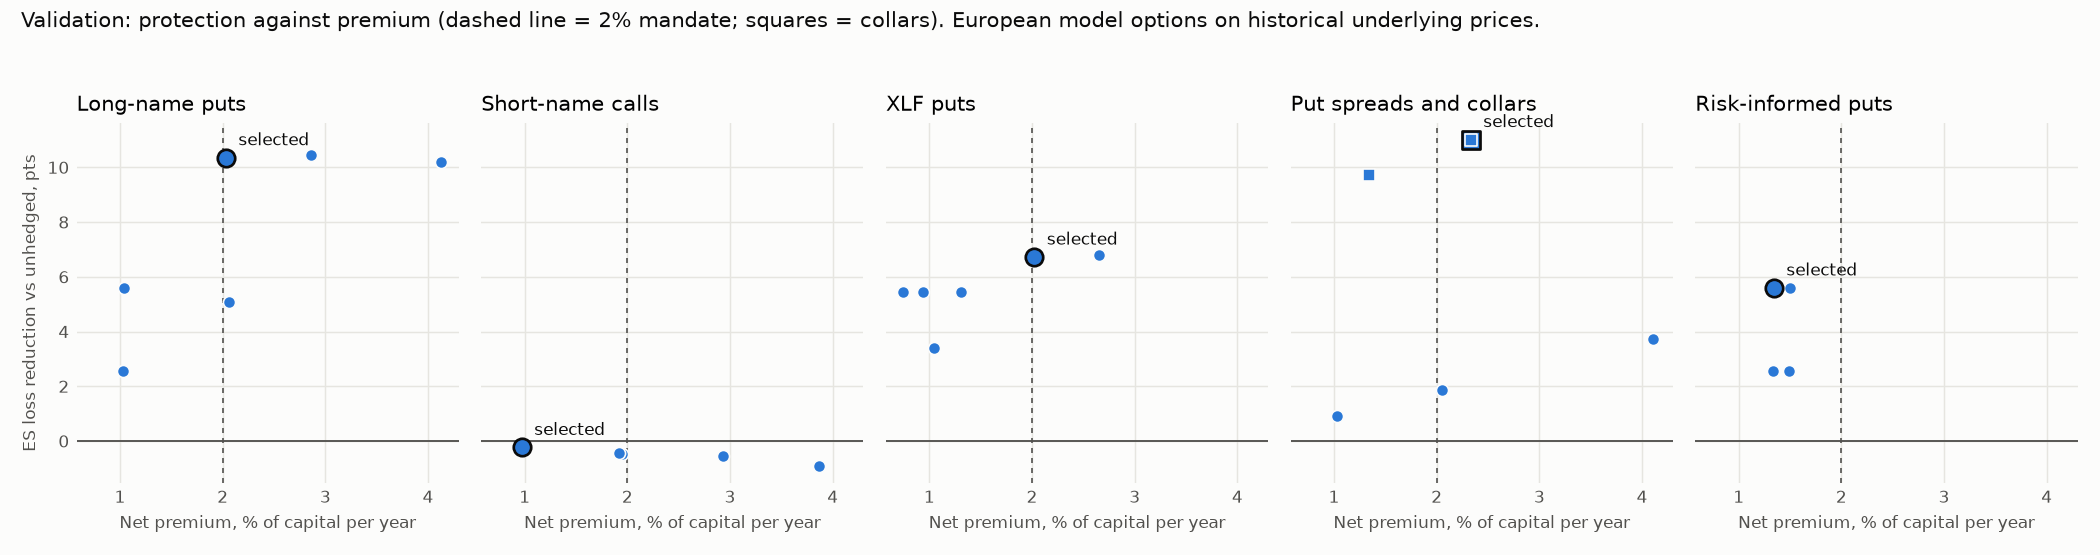

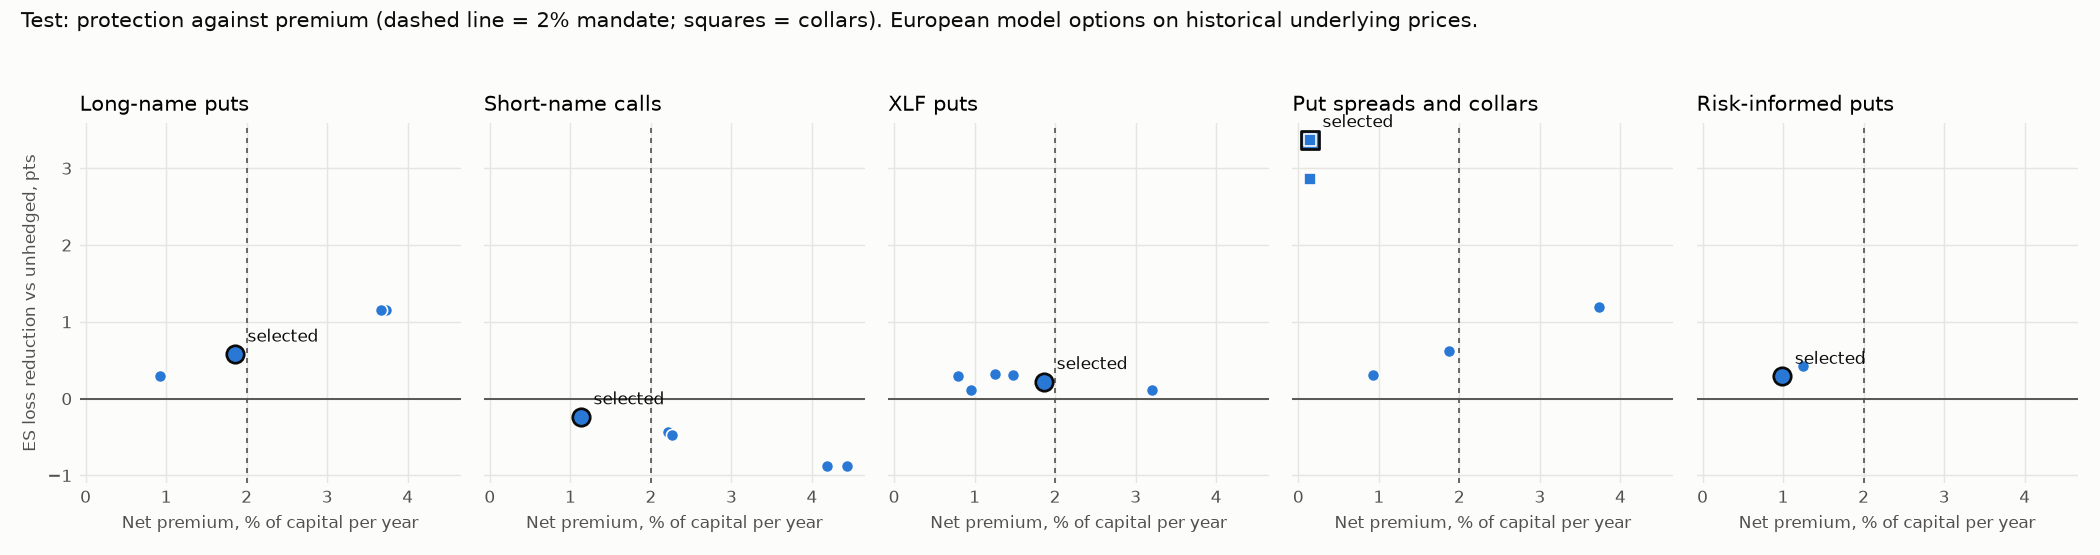

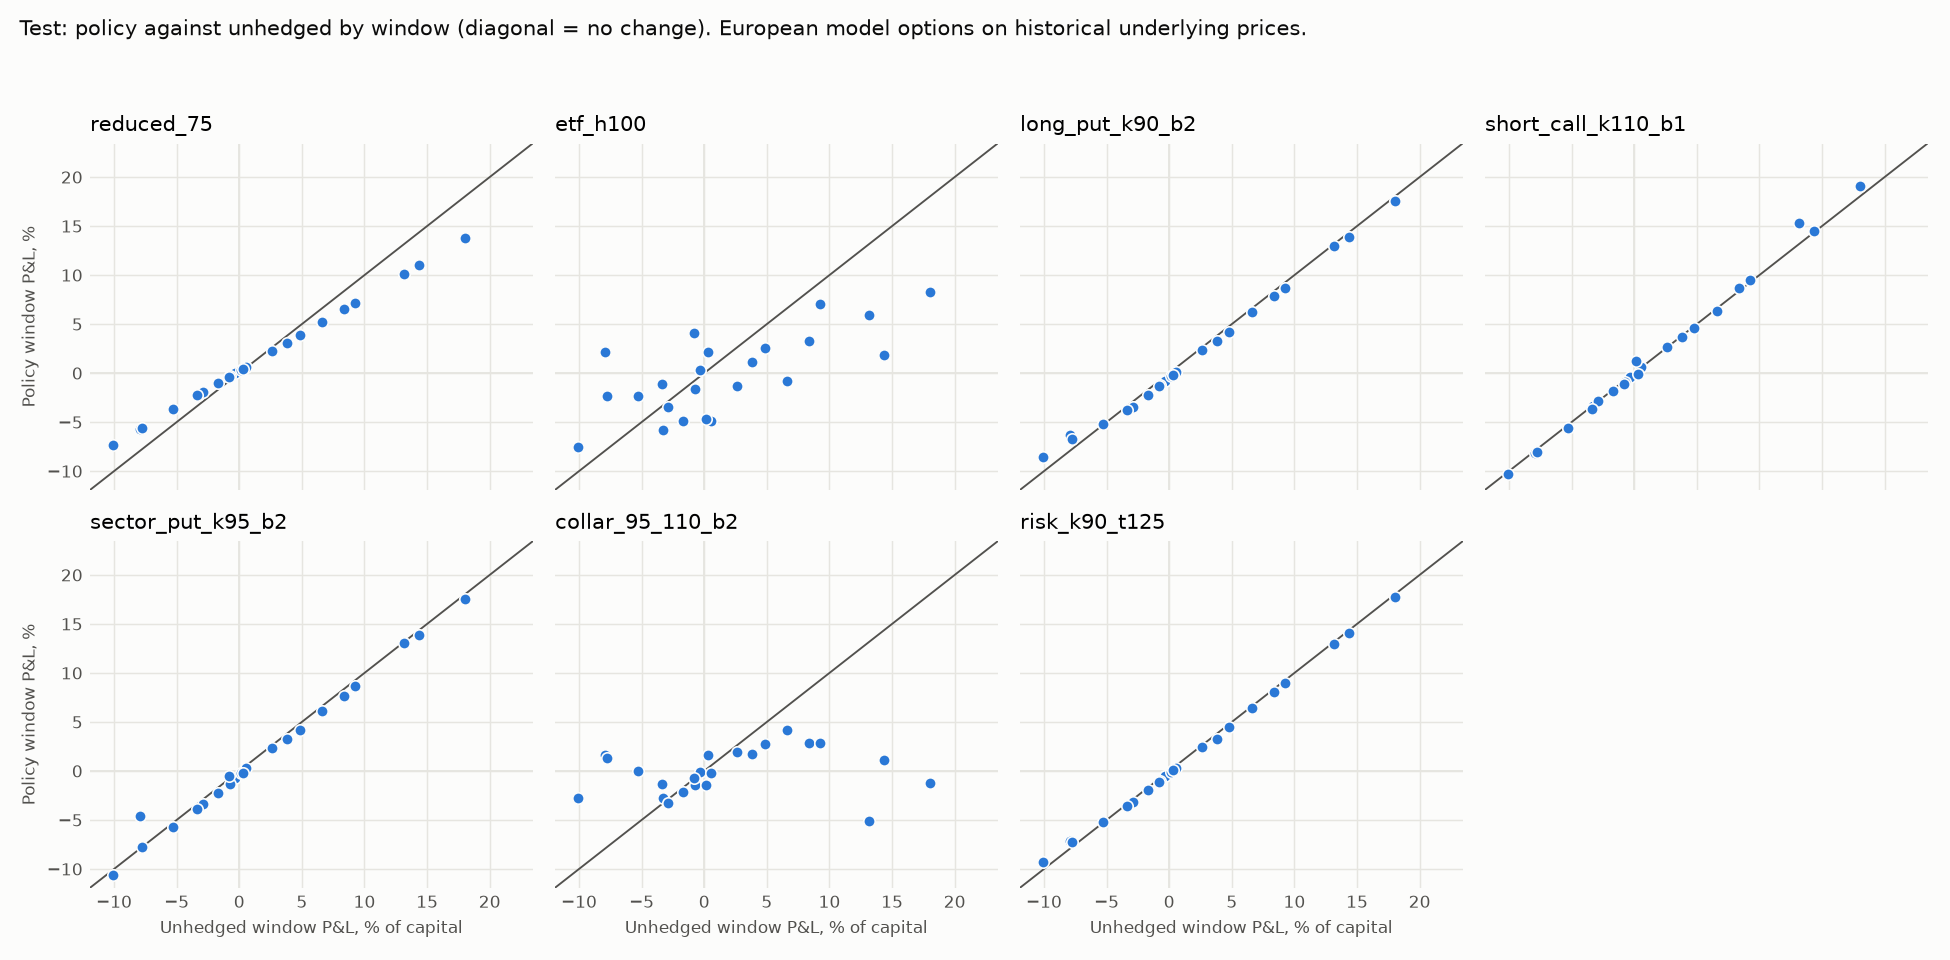

,label,long_equity,short_equity,etf_sleeve,options,interest,stock_costs,total
0,unhedged,3.499,-2.219,0.000,0.000,0.498,-0.134,1.644
1,reduced_75,2.624,-1.664,0.000,0.000,0.625,-0.100,1.484
2,etf_h100,3.499,-2.219,-2.339,0.000,1.175,-0.202,-0.086
3,long_put_k90_b2,3.499,-2.219,0.000,-0.188,0.493,-0.134,1.451
4,short_call_k110_b1,3.499,-2.219,0.000,0.096,0.495,-0.134,1.738
5,sector_put_k95_b2,3.499,-2.219,0.000,-0.241,0.493,-0.134,1.399
6,collar_95_110_b2,3.499,-2.219,0.000,-1.677,0.497,-0.134,-0.033
7,risk_k90_t125,3.499,-2.219,0.000,-0.110,0.495,-0.134,1.532


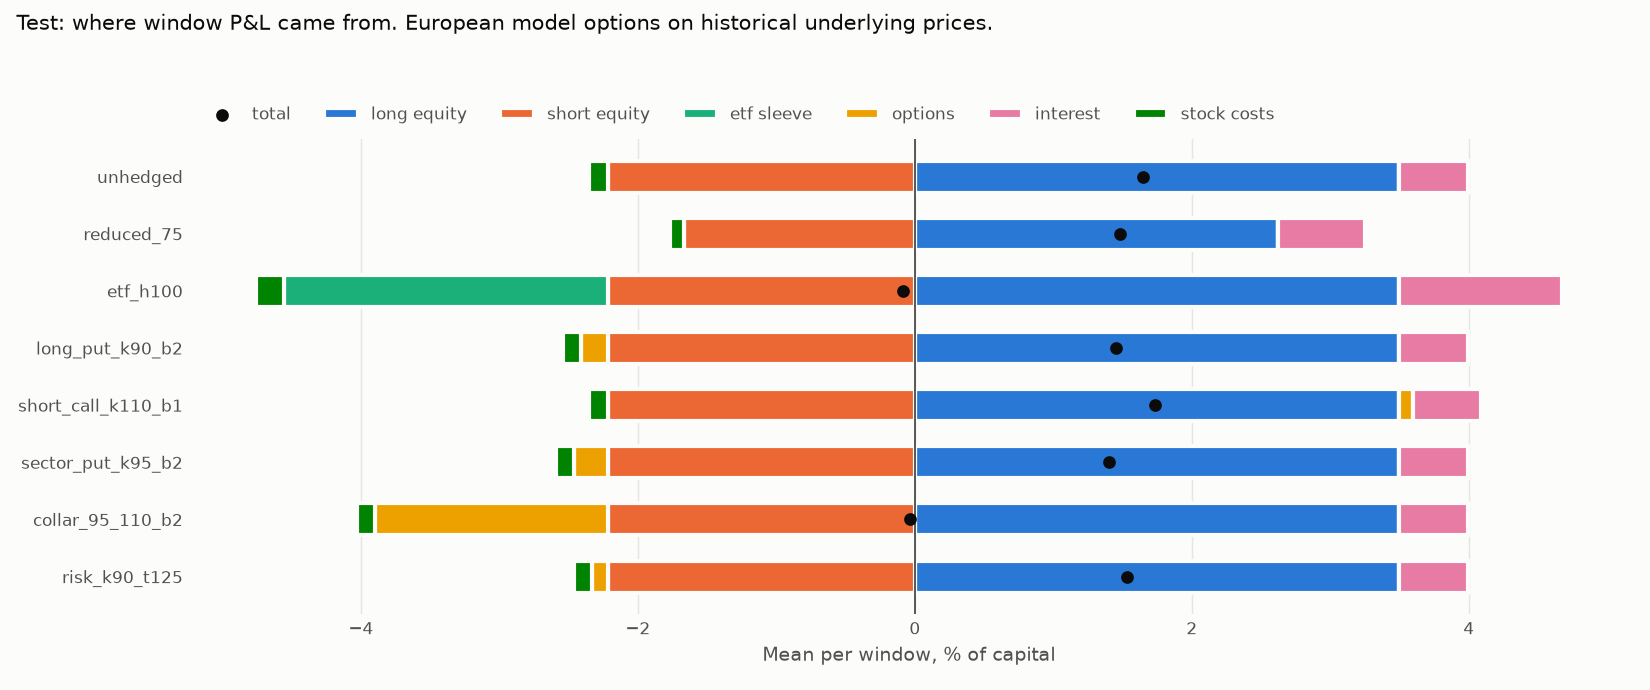

,split,label,n_windows,tail_windows,mean_difference_pct,mean_lower_pct,mean_upper_pct,mean_ex_best_window_pct,best_window_key,es_difference_pct,es_lower_pct,es_upper_pct,evidence
0,validation,reduced_75,11,3,0.417,-0.564,1.383,-0.263,validation-008,-3.346,-7.212,-0.710,exploratory
1,validation,etf_h100,11,3,0.390,-1.907,2.554,-1.507,validation-008,-6.997,-19.360,0.502,exploratory
2,validation,long_put_k90_b2,11,3,2.686,-0.298,7.507,0.065,validation-008,-10.351,-26.642,-0.127,exploratory
3,validation,short_call_k110_b1,11,3,-0.029,-0.227,0.217,-0.146,validation-007,0.236,0.197,0.271,exploratory
4,validation,sector_put_k95_b2,11,3,1.455,-0.448,4.050,-0.017,validation-008,-6.720,-16.175,0.337,exploratory
5,validation,collar_95_110_b2,11,3,2.809,-0.999,6.827,-0.606,validation-008,-11.014,-25.227,-0.769,exploratory
6,validation,risk_k90_t125,11,3,1.276,-0.214,3.690,-0.040,validation-008,-5.592,-14.440,-0.095,exploratory
7,test,reduced_75,23,6,-0.160,-0.807,0.543,-0.293,test-016,-1.821,-2.381,-0.922,exploratory
8,test,etf_h100,23,6,-1.731,-3.713,0.311,-2.270,test-005,-1.048,-3.523,2.158,exploratory
9,test,long_put_k90_b2,23,6,-0.193,-0.421,0.060,-0.276,test-005,-0.580,-1.346,0.247,exploratory


,split,episode,windows,start,end,worst_pnl_pct
8,test,1,3,2021-10-04,2022-07-06,-7.93
9,test,2,1,2023-01-04,2023-04-05,-7.78
10,test,3,1,2023-07-07,2023-10-05,-3.34
11,test,4,1,2025-01-07,2025-04-09,-10.05


**Protection on the protected side, in windows where that side lost money**

,split,label,side,side_loss_windows,windows,mean_side_loss_pct,mean_with_option_pct,worst_side_loss_pct,worst_with_option_pct,side_loss_capture,windows_option_paid
0,validation,long_put_k90_b2,long,6,11,-11.002,-5.595,-41.223,-12.322,0.509,5
1,validation,short_call_k110_b1,short,3,11,-8.280,-7.713,-10.051,-9.547,0.931,3
2,validation,collar_95_110_b2,long,6,11,-11.002,-2.446,-41.223,-4.899,0.222,6
3,validation,risk_k90_t125,long,6,11,-11.002,-8.313,-41.223,-26.779,0.756,5
4,test,long_put_k90_b2,long,8,23,-8.026,-7.703,-14.574,-12.965,0.960,7
5,test,short_call_k110_b1,short,16,23,-4.854,-4.592,-11.463,-9.369,0.946,14
6,test,collar_95_110_b2,long,8,23,-8.026,-3.627,-14.574,-5.406,0.452,8
7,test,risk_k90_t125,long,8,23,-8.026,-7.865,-14.574,-13.755,0.980,7


**ES loss reduction against unhedged, points. Budgets stay fixed, so dearer options buy less coverage.**

scenario                         base  rate_0.00  reactive  vol_x1.25  vol_x1.50  window_21
split      label                                                                           
test       collar_95_110_b2     3.373      2.393     3.558      3.462      3.557      0.861
           etf_h100             1.048      0.337     1.048      1.048      1.048      1.268
           long_put_k90_b2      0.580      0.456     0.437      0.156     -0.041      0.693
           reduced_75           1.821      1.693     1.821      1.821      1.821      1.179
           risk_k90_t125        0.290      0.228     0.218      0.078     -0.020      0.349
           sector_put_k95_b2    0.222      0.119     0.005     -0.024     -0.149      0.249
           short_call_k110_b1  -0.237     -0.232    -0.238     -0.242     -0.244     -0.085
validation collar_95_110_b2    11.014      9.296    11.051     10.974     10.975      2.342
           etf_h100             6.997      6.382     6.997      6.997      6.997      4.332
           long_put_k90_b2     10.351      9.136    10.294      5.612      3.402      3.063
           reduced_75           3.346      3.221     3.346      3.346      3.346      1.812
           risk_k90_t125        5.592      4.567     5.588      2.804      1.699      3.048
           sector_put_k95_b2    6.720      5.350     6.720      3.968      2.649      1.768
           short_call_k110_b1  -0.236     -0.233    -0.236     -0.239     -0.241     -0.099

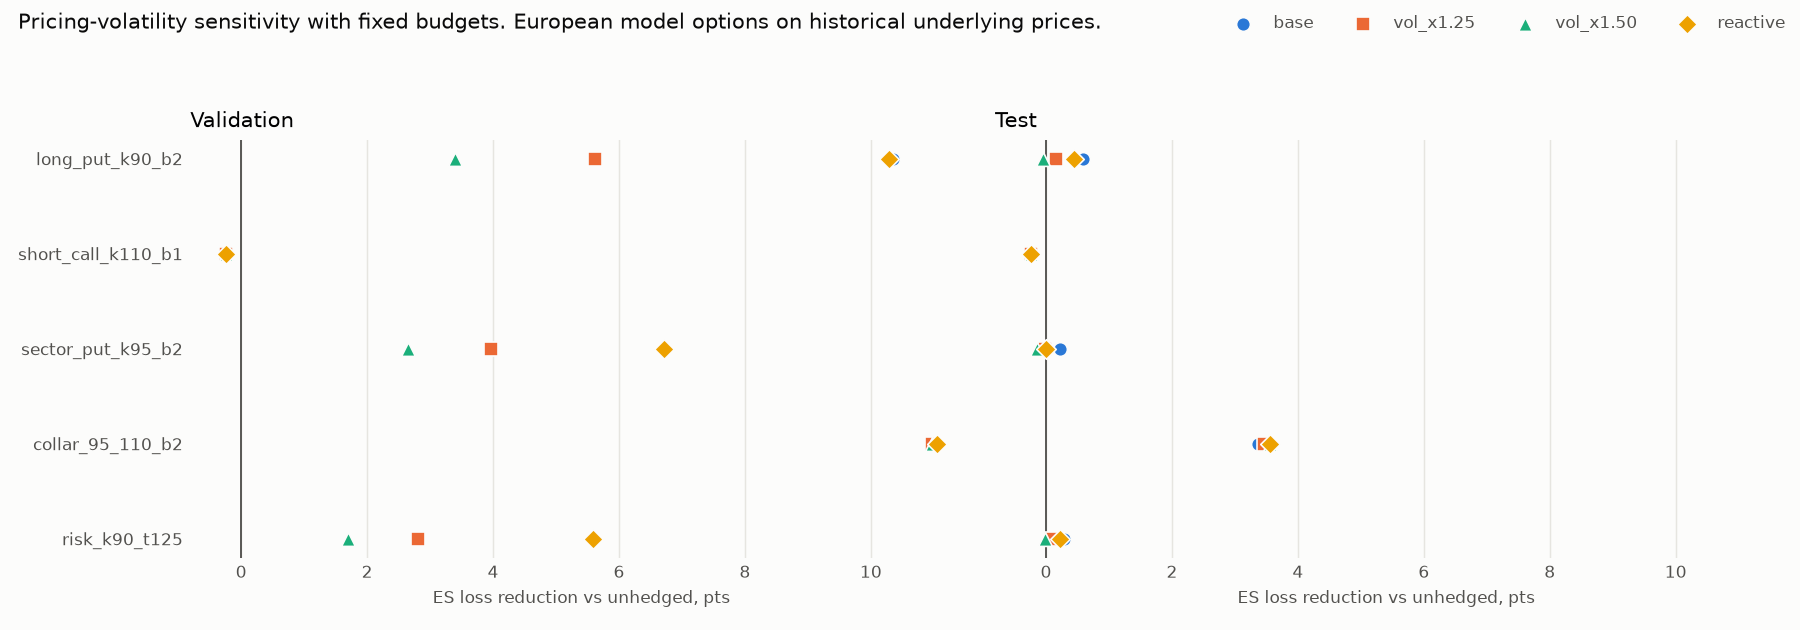

**Sector basis: the six worst test windows, % of capital**

,key,split,start,end,book_pnl_pct,long_equity_pnl_pct,short_equity_pnl_pct,sector_option_pnl_pct,name_option_pnl_pct
54,test-016,test,2025-01-07,2025-04-09,-10.05,-12.10,1.68,-0.53,1.54
43,test-005,test,2022-04-04,2022-07-06,-7.93,-14.57,6.26,3.30,1.64
46,test-008,test,2023-01-04,2023-04-05,-7.78,-13.99,5.85,0.05,1.02
42,test-004,test,2022-01-03,2022-04-04,-5.27,-10.65,5.03,-0.40,0.11
48,test-010,test,2023-07-07,2023-10-05,-3.34,-6.00,2.29,-0.49,-0.37
41,test-003,test,2021-10-04,2022-01-03,-3.32,-0.06,-3.62,-0.57,-0.44


,case,window,policy,live_terminal_nav,stored_terminal_nav,difference
0,long downside,test-005,long_put_k90_b2,9.370277e+07,9.370277e+07,0.0
1,short upside,test-017,short_call_k110_b1,1.152715e+08,1.152715e+08,0.0


,case,stage,item,hand,ledger,residual
0,long downside,inception,stock cash flow,-5.033266e+07,-5.033266e+07,0.0
1,long downside,inception,option premium cash flow,-4.926479e+05,-4.926479e+05,-0.0
2,long downside,inception,stock cost,6.500212e+04,6.500212e+04,0.0
3,long downside,inception,cash,4.910969e+07,4.910969e+07,-0.0
4,long downside,inception,nav,9.993500e+07,9.993500e+07,0.0
5,long downside,adverse 2022-06-30,cash,4.957964e+07,4.957964e+07,0.0
6,long downside,adverse 2022-06-30,stock value,4.152348e+07,4.152348e+07,-0.0
7,long downside,adverse 2022-06-30,option value,2.281851e+06,2.281851e+06,0.0
8,long downside,adverse 2022-06-30,nav,9.338497e+07,9.338497e+07,0.0
9,long downside,expiry,option settlement,2.130700e+06,2.130700e+06,0.0


Largest hand residual: $ 1.49e-08


,16,11
case,test_short_upside,test_long_downside
window,test-017,test-005
underlying,GS,BAC
kind,call,put
book_shares,-21634.0,366748.0
contracts,52.0,1446.0
covered_fraction,0.24,0.394
strike,508.442,36.81
decision_close,462.22,40.9
execution_close,516.87,40.83


,gate,status,evidence
0,Fixed 6-10-name long/short book,passed,"10 names, gross and net validated against issu..."
1,Calendar and coverage alignment,passed,"4236 sessions, exchange calendar match: True"
2,Protocol frozen and hashed before test,passed,Selection saw prices through 2020-12-31
3,Test evaluated once with no later changes,passed,"1 logged attempt(s), changed files: []"
4,Model-contract accounting,passed,All window checks true: True; largest hand res...
5,All eight comparisons evaluated,passed,Test families evaluated: 8; missing: []
6,Statistical evidence of protection,exploratory,23 test windows and 6 tail windows
7,Continuous rolled portfolio NAV,not_available,replay opens all options at inception; separat...
8,Listed-option execution backtest,blocked,No verified historical option quotes; results ...
9,"Dividends, borrow, margin, option spreads, Ame...",not_modeled,Not supported by replay or the price inputs


- No historical option quotes or observed implied volatilities. Option prices are Black-Scholes values at an assumed volatility with no skew or term structure.
- No option bid/ask charge, because replay has no option execution cost. Purchased protection is therefore flattered.
- European cash settlement only. Listed single-name options are American and physically settled.
- Split-adjusted closes are not total returns. Dividends received on longs, owed on shorts and owed on a short ETF are excluded, and the option model has no dividend yield.
- No stock borrow fee, short rebate spread or margin requirement. Short proceeds earn the full constant rate.
- The rate is a constant illustrative 4%, including years when short rates were near zero.
- Issuers are current survivors. Historical membership is unavailable, so failed and acquired banks are absent.
- Each window is a separate account that buys and liquidates the whole book, which overstates stock turnover against a rolled book.
- Holdi

In [1]:
from hedging_harness.notebook_views import run
_ = run('07_equity_overlay_study')


## 2. The fixed book and the windows

All ten panel issuers are held, so no issuer was chosen or dropped. Deposit-funded banks are long and capital-markets, brokerage and custody franchises are short. This is a mandate for studying overlays, not an alpha view.

Each window is a separate account opened with the same capital, so results below are per window. Nothing here is a chained NAV, CAGR or full-period drawdown.

## 3. What validation selected

Validation chose one candidate per family by lowest expected shortfall (the mean loss of the worst 25% of windows), within a 2% annual budget. Validation has only 11 windows, and one of them, Q1 2020, dominates the choice.

## 4. Test results

Downside capture is the policy's loss over the unhedged loss in windows where the unhedged book lost money, so lower is better. Upside retained is the same ratio in windows where it gained, so higher is better.

The exposure table matters as much as the risk table. The collar has a delta-adjusted net exposure near zero, so most of its protection comes from selling the book's exposure rather than from insurance. The ETF hedge goes further, to a net short delta. Neither is like-for-like with a small protective overlay.

## 5. Uncertainty, tails and sensitivity

Differences against unhedged are computed per window, so issuers in one episode are never separate observations. Intervals come from a circular block bootstrap over chronological windows and are pointwise. Every row is labelled exploratory: the test has 23 windows, six tail windows and four distinct tail episodes.

## 6. Reproduce and reconcile

This section rebuilds accounts from raw closes. It re-runs the worst long-side and short-side test windows with their frozen policies, compares them with the stored rows, and repeats the hand reconciliation. The policies and windows are already fixed, so this is a reproducibility check and not a new evaluation.

## 7. Gates and limits

Passing accounting checks does not establish that these policies work in listed-option markets. The gate table separates what passed from what stays model-only, exploratory or blocked.